# 3 · 深度學習壓縮:AE / VAE / Conv-VAE(CNN)

統計法是固定公式;神經網路**學**壓縮。三種:

- **AE**(表格):非線性瓶頸,重建最省維。
- **VAE**(表格):潛空間加 N(0,I) 先驗 → 可生成/採樣。
- **Conv-VAE**(影像/CNN):吃高度 patch,卷積看**空間紋理**——urban form 最自然的 NN 表示。

訓練完**存檔**到 `out/models/`,NB4/NB5 直接載入不重訓。

## 環境 + 兩種資料

In [6]:
import sys, os
from pathlib import Path
_here = Path(os.getcwd()).resolve()
_r07 = next((p for p in [_here, *_here.parents] if (p / 'nn').exists()), _here)
if str(_r07) not in sys.path: sys.path.insert(0, str(_r07))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
import nn                       # 建築層 + 中文字型自動修好
print('07 根:', _r07)
from nn import conv, io, raster

07 根: C:\baidunetdiskdownload\power_to_form\DF26_ws18\07_Latent_Urban


In [7]:
SLUG = 'lujiazui'
X, feat_names, aux = nn.make_dataset(SLUG)          # 表格
SLUGS = ['lujiazui','caoyang','yuyuan','waitan','nanjingxi','kongjiang',
         'pengpu','laoximen','dapuqiao','xujiahui','nanjingdong','beiwaitan']
Ximg, labels = raster.city_patch_dataset(SLUGS, patch=64, stride=16)  # 影像
print('表格', X.shape, '| 影像 patch', Ximg.shape)

表格 (3263, 16) | 影像 patch (993, 1, 64, 64)


## A. 表格 AE / VAE
訓練,看重建誤差。VAE loss 高於 AE 是正常的(多了 KL 正則,換來可生成)。

AE  recon MSE 0.0475  (最終loss 0.0475)
VAE recon MSE 0.3539  (最終loss 0.3538)


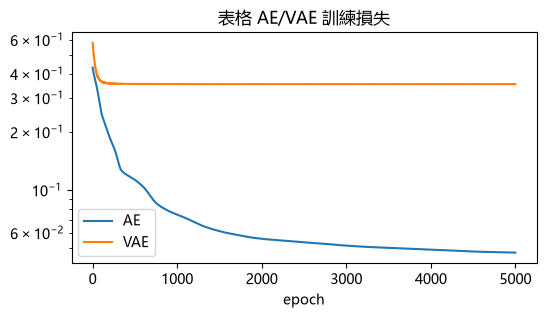

In [8]:
# 07 的 nn.train_ae(X) 會自建並回傳 (模型, 每回合loss);潛維由 config.LATENT_DIM(=2)決定
ae, ae_losses = nn.train_ae(X, epochs=5000)
vae, vae_losses = nn.train_vae(X, epochs=5000, beta=1.0)
ae_mse = ((ae.reconstruct(X) - X)**2).mean()
vae_mse = ((vae.reconstruct(X) - X)**2).mean()
print('AE  recon MSE %.4f  (最終loss %.4f)' % (ae_mse, ae_losses[-1]))
print('VAE recon MSE %.4f  (最終loss %.4f)' % (vae_mse, vae_losses[-1]))
fig, ax = plt.subplots(figsize=(6,3))
ax.plot(ae_losses, label='AE'); ax.plot(vae_losses, label='VAE')
ax.set_yscale('log'); ax.legend(); ax.set_xlabel('epoch'); ax.set_title('表格 AE/VAE 訓練損失'); plt.show()

## B. Conv-VAE(CNN):看空間紋理
卷積編碼高度 patch → 潛向量 → 反卷積解回。稀疏高度圖易 **posterior collapse**,
用 `pos_weight`(建築像素加權)逼模型學建築位置。

  ep  0 total=0.2905 recon=0.2839 kl=1.3236
  ep 10 total=0.0938 recon=0.0913 kl=0.0468
  ep 20 total=0.0926 recon=0.0907 kl=0.0191
  ep 30 total=0.0927 recon=0.0910 kl=0.0164
  ep 40 total=0.0926 recon=0.0907 kl=0.0188
  ep 50 total=0.0923 recon=0.0901 kl=0.0223
  ep 60 total=0.0926 recon=0.0897 kl=0.0295
  ep 70 total=0.0926 recon=0.0898 kl=0.0284
  ep 79 total=0.0925 recon=0.0895 kl=0.0295


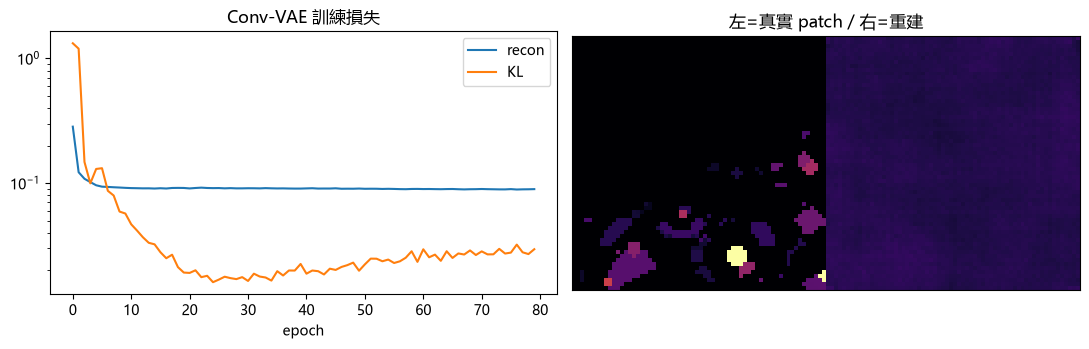

In [9]:
cvae = conv.ConvVAE(latent=8)
hist = conv.train_conv_vae(cvae, Ximg, epochs=80, beta=0.1, pos_weight=9, verbose=True)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(hist['recon'], label='recon'); ax[0].plot(hist['kl'], label='KL')
ax[0].set_yscale('log'); ax[0].legend(); ax[0].set_title('Conv-VAE 訓練損失'); ax[0].set_xlabel('epoch')
rec = conv.reconstruct(cvae, Ximg[:1])[0,0]
ax[1].imshow(np.concatenate([Ximg[0,0], rec], 1), cmap='inferno')
ax[1].set_title('左=真實 patch / 右=重建'); ax[1].set_xticks([]); ax[1].set_yticks([])
fig.tight_layout(); plt.show()

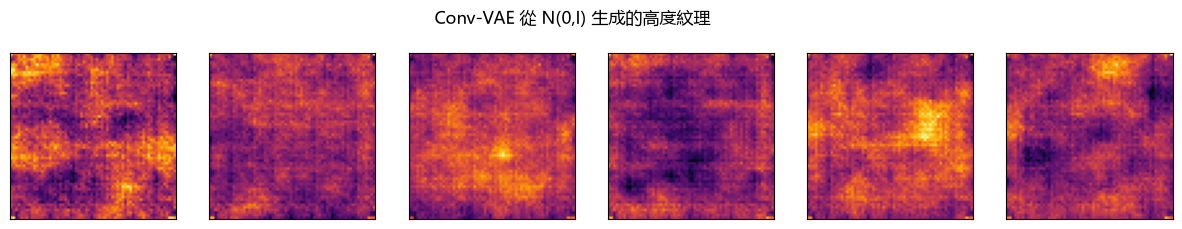

In [10]:
# 從先驗採樣:Conv-VAE 生成沒看過的高度紋理
S = conv.sample(cvae, 6, seed=1)
fig, ax = plt.subplots(1, 6, figsize=(15, 2.6))
for a, s in zip(ax, S):
    a.imshow(s[0], cmap='inferno'); a.set_xticks([]); a.set_yticks([])
fig.suptitle('Conv-VAE 從 N(0,I) 生成的高度紋理'); plt.show()

## C. 存檔:訓練一次,後續重用

In [11]:
io.save_model(ae,  'ae_lujiazui',  {'kind':'AE','input_dim':int(X.shape[1]),'latent':2,'slug':SLUG})
io.save_model(vae, 'vae_lujiazui', {'kind':'VAE','input_dim':int(X.shape[1]),'latent':2,'slug':SLUG})
io.save_model(cvae,'conv_vae',     {'kind':'ConvVAE','latent':8,'patch':64})
print('已存到', io.MODELS)
print(sorted(p.name for p in io.MODELS.glob('*.pt')))

已存到 C:\baidunetdiskdownload\power_to_form\DF26_ws18\07_Latent_Urban\out\models
['ae_lujiazui.pt', 'conv_vae.pt', 'vae_lujiazui.pt']


## 小結
- **AE** 重建最省維;**VAE** 換來可生成;**Conv-VAE** 看空間紋理、能生成整片高度圖。
- 模型已存檔 → NB4 分析潛空間、NB5 生成都直接載入。
- NN 啟發:換**表示**(表格→影像)+ 換**架構**(MLP→CNN),同資料能學到不同層次的都市形態。